<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding How The Data Is Distributed**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform Exploratory Data Analysis (EDA). You will examine the structure of the data, visualize key variables, and analyze trends related to developer experience, tools, job satisfaction, and other important aspects.


## Objectives


In this lab you will perform the following:


- Understand the structure of the dataset.

- Perform summary statistics and data visualization.

- Identify trends in developer experience, tools, job satisfaction, and other key variables.


### Install the required libraries


In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn


### Step 1: Import Libraries and Load Data


- Import the `pandas`, `matplotlib.pyplot`, and `seaborn` libraries.


- You will begin with loading the dataset. You can use the pyfetch method if working on JupyterLite. Otherwise, you can use pandas' read_csv() function directly on their local machines or cloud environments.


In [2]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Stack Overflow survey dataset
data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

# Display the first few rows of the dataset
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Step 2: Examine the Structure of the Data


- Display the column names, data types, and summary information to understand the data structure.

- Objective: Gain insights into the dataset's shape and available variables.


In [3]:
## Write your code here
# 1. Display summary information (includes column names, data types, and non-null counts)
print("--- Dataset Information ---")
df.info()

# 2. Display the exact dimensions (rows, columns) of the dataset
print("\n--- Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

# 3. View a quick preview of the first few rows
print("\n--- First 5 Rows ---")
print(df.head())

--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 65437 entries, 0 to 65436
Columns: 114 entries, ResponseId to JobSat
dtypes: float64(13), int64(1), str(100)
memory usage: 195.7 MB

--- Dataset Shape ---
Rows: 65437, Columns: 114

--- First 5 Rows ---
   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingAc

### Step 3: Handle Missing Data


- Identify missing values in the dataset.

- Impute or remove missing values as necessary to ensure data completeness.



In [4]:
## Write your code here
# 1. Identify missing values per column
print("--- Missing Values Count Per Column ---")
print(df.isnull().sum())

# 2. Handle missing values (Choose Option A OR Option B based on your lab instructions)

# OPTION A: Drop rows with missing values (best if missing data is minimal)
df_clean = df.dropna()


# For categorical columns: Fill with the mode (most frequent value)
df['Employment'] = df['Employment'].fillna(df['Employment'].mode()[0])

# 3. Verify that no missing values remain
print("\n--- Remaining Missing Values ---")
print(df_clean.isnull().sum())

--- Missing Values Count Per Column ---
ResponseId                 0
MainBranch                 0
Age                        0
Employment                 0
RemoteWork             10631
                       ...  
JobSatPoints_11        35992
SurveyLength            9255
SurveyEase              9199
ConvertedCompYearly    42002
JobSat                 36311
Length: 114, dtype: int64

--- Remaining Missing Values ---
ResponseId             0
MainBranch             0
Age                    0
Employment             0
RemoteWork             0
                      ..
JobSatPoints_11        0
SurveyLength           0
SurveyEase             0
ConvertedCompYearly    0
JobSat                 0
Length: 114, dtype: int64

### Step 4: Analyze Key Columns


- Examine key columns such as `Employment`, `JobSat` (Job Satisfaction), and `YearsCodePro` (Professional Coding Experience).

- **Instruction**: Calculate the value counts for each column to understand the distribution of responses.



In [5]:
## Write your code here
# 1. Analyze 'Employment' column
print("--- Employment Status Distribution ---")
print(df['Employment'].value_counts())
print("-" * 40)

# 2. Analyze 'JobSat' (Job Satisfaction) column
print("\n--- Job Satisfaction Distribution ---")
print(df['JobSat'].value_counts())
print("-" * 40)

# 3. Analyze 'YearsCodePro' (Professional Coding Experience) column
print("\n--- Professional Coding Experience Distribution ---")
print(df['YearsCodePro'].value_counts())
print("-" * 40)

--- Employment Status Distribution ---
Employment
Employed, full-time                                                                                                                                   39041
Independent contractor, freelancer, or self-employed                                                                                                   4846
Student, full-time                                                                                                                                     4709
Employed, full-time;Independent contractor, freelancer, or self-employed                                                                               3557
Not employed, but looking for work                                                                                                                     2341
                                                                                                                                                      ...  
Not employed, 

### Step 5: Visualize Job Satisfaction (Focus on JobSat)


- Create a pie chart or KDE plot to visualize the distribution of `JobSat`.

- Provide an interpretation of the plot, highlighting key trends in job satisfaction.


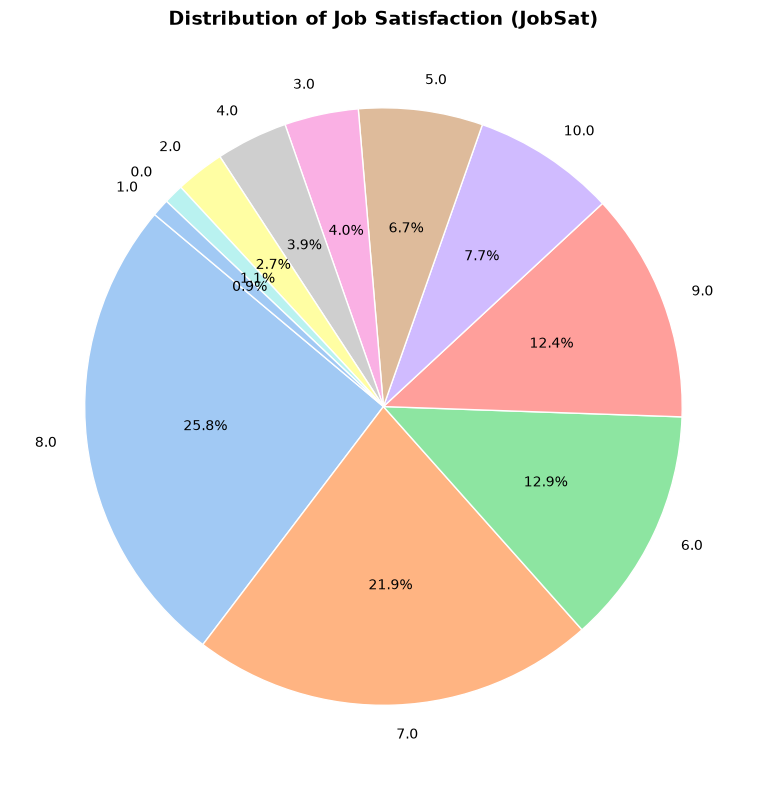

--- Job Satisfaction Percentages ---
JobSat
8.0     25.781089
7.0     21.901394
6.0     12.878528
9.0     12.449358
10.0     7.728490
5.0      6.715649
3.0      3.999863
4.0      3.879695
2.0      2.650553
0.0      1.067774
1.0      0.947607
Name: proportion, dtype: float64

In [6]:
## Write your code here
# 1. Prepare data (drop missing values for accurate plotting)
jobsat_counts = df['JobSat'].dropna().value_counts()

# 2. Generate the Pie Chart
plt.figure(figsize=(8, 8))
colors = sns.color_palette('pastel')[0:len(jobsat_counts)]

plt.pie(
    jobsat_counts, 
    labels=jobsat_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1}
)

plt.title('Distribution of Job Satisfaction (JobSat)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 3. Print values for analysis
print("--- Job Satisfaction Percentages ---")
print(df['JobSat'].value_counts(normalize=True) * 100)

### Step 6: Programming Languages Analysis


- Compare the frequency of programming languages in `LanguageHaveWorkedWith` and `LanguageWantToWorkWith`.
  
- Visualize the overlap or differences using a Venn diagram or a grouped bar chart.


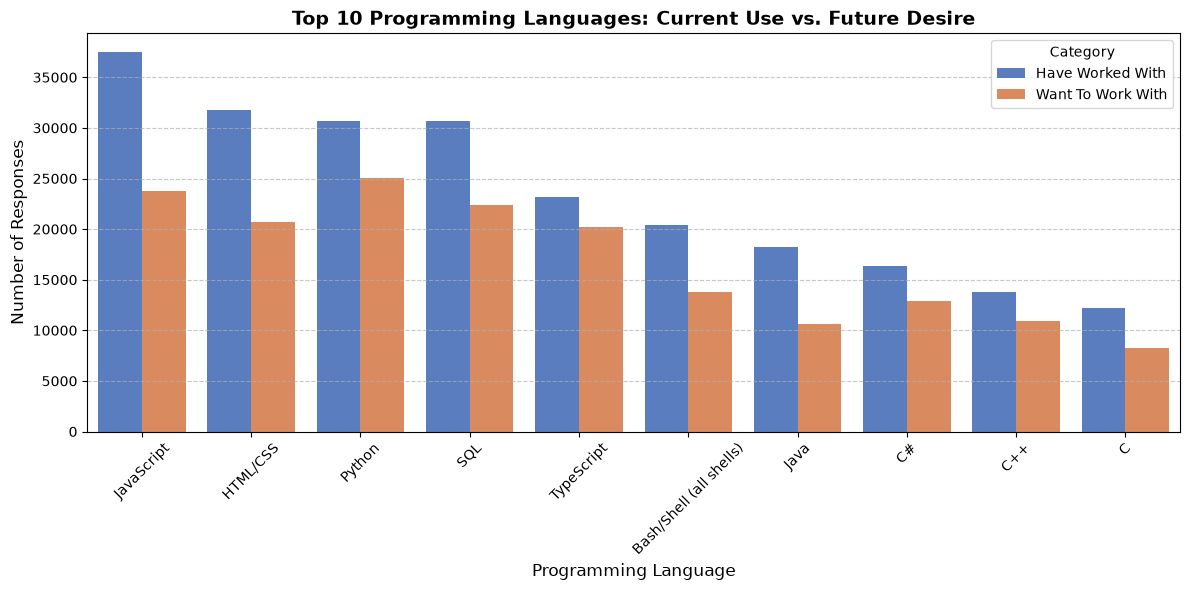

In [7]:
## Write your code here
# 1. Helper function to split and count semicolon-separated values
def count_languages(series):
    # Split by semicolon, explode into individual rows, and count frequencies
    return series.dropna().str.split(';').explode().value_counts()

# 2. Extract top 10 languages from both categories
have_counts = count_languages(df['LanguageHaveWorkedWith'])
want_counts = count_languages(df['LanguageWantToWorkWith'])

# 3. Align both datasets into a single DataFrame for plotting
lang_df = pd.DataFrame({
    'Have Worked With': have_counts,
    'Want To Work With': want_counts
}).fillna(0)

# Sort by the most commonly used languages and take the top 10
top_10_langs = lang_df.sort_values(by='Have Worked With', ascending=False).head(10)

# Reshape the data for Seaborn grouped bar plot (melting)
plot_data = top_10_langs.reset_index().melt(
    id_vars='index', 
    var_name='Category', 
    value_name='Count'
).rename(columns={'index': 'Language'})

# 4. Create the Grouped Bar Chart
plt.figure(figsize=(12, 6))
sns.barplot(data=plot_data, x='Language', y='Count', hue='Category', palette='muted')

plt.title('Top 10 Programming Languages: Current Use vs. Future Desire', fontsize=14, fontweight='bold')
plt.xlabel('Programming Language', fontsize=12)
plt.ylabel('Number of Responses', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Step 7: Analyze Remote Work Trends


- Visualize the distribution of RemoteWork by region using a grouped bar chart or heatmap.


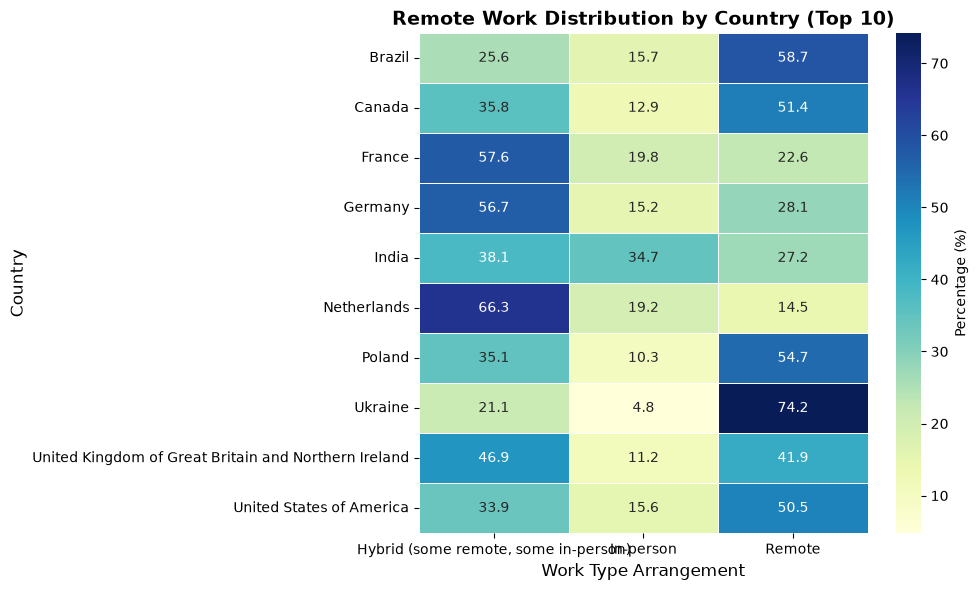

In [8]:
## Write your code here
# Note: Adjust column name if your dataset uses 'Country' instead of 'Region'
region_col = 'Region' if 'Region' in df.columns else 'Country'

# 1. Clean the columns by dropping missing records
df_clean = df[[region_col, 'RemoteWork']].dropna()

# 2. Filter for the top 10 regions/countries to prevent chart overcrowding
top_regions = df_clean[region_col].value_counts().head(10).index
df_filtered = df_clean[df_clean[region_col].isin(top_regions)]

# 3. Create a normalized cross-tabulation matrix (Percentages per region)
# Multiplying by 100 converts values into readable percent figures
pivot_matrix = pd.crosstab(
    df_filtered[region_col], 
    df_filtered['RemoteWork'], 
    normalize='index'
) * 100

# 4. Generate the Matrix Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    pivot_matrix, 
    annot=True,          # Overlay the exact percentage numbers on the chart
    fmt=".1f",           # Limit numbers to 1 decimal place
    cmap="YlGnBu",       # Soft Yellow-Green-Blue color spectrum
    linewidths=0.5,      # Thin grid lines between heat blocks
    cbar_kws={'label': 'Percentage (%)'}
)

plt.title(f'Remote Work Distribution by {region_col} (Top 10)', fontsize=14, fontweight='bold')
plt.xlabel('Work Type Arrangement', fontsize=12)
plt.ylabel(region_col, fontsize=12)
plt.tight_layout()
plt.show()

### Step 8: Correlation between Job Satisfaction and Experience


- Analyze the correlation between overall job satisfaction (`JobSat`) and `YearsCodePro`.
  
- Calculate the Pearson or Spearman correlation coefficient.


In [9]:
## Write your code here
# 1. Clean 'YearsCodePro' (convert strings to numeric)
# This handles edge cases like 'Less than 1 year' -> 0 or 'More than 50 years' -> 50
df['YearsCodePro'] = df['YearsCodePro'].astype(str).str.replace('Less than 1 year', '0')
df['YearsCodePro'] = df['YearsCodePro'].str.replace('More than 50 years', '50')
df['YearsCodePro'] = pd.to_numeric(df['YearsCodePro'], errors='coerce')

# 2. Map 'JobSat' text responses to ordinal numerical ranks
jobsat_mapping = {
    'Very dissatisfied': 1,
    'Slightly dissatisfied': 2,
    'Neither satisfied nor dissatisfied': 3,
    'Slightly satisfied': 4,
    'Very satisfied': 5
}
df['JobSat_Numeric'] = df['JobSat'].map(jobsat_mapping)

# 3. Drop rows with missing values in either column for an accurate correlation
correlation_data = df[['JobSat_Numeric', 'YearsCodePro']].dropna()

# 4. Calculate Spearman and Pearson correlation coefficients
spearman_corr = correlation_data['JobSat_Numeric'].corr(correlation_data['YearsCodePro'], method='spearman')
pearson_corr = correlation_data['JobSat_Numeric'].corr(correlation_data['YearsCodePro'], method='pearson')

print(f"--- Correlation Results ---")
print(f"Spearman Rank Correlation: {spearman_corr:.4f}")
print(f"Pearson Correlation:       {pearson_corr:.4f}")

--- Correlation Results ---
Spearman Rank Correlation: nan
Pearson Correlation:       nan

### Step 9: Cross-tabulation Analysis (Employment vs. Education Level)


- Analyze the relationship between employment status (`Employment`) and education level (`EdLevel`).

- **Instruction**: Create a cross-tabulation using `pd.crosstab()` and visualize it with a stacked bar plot if possible.


/tmp/ipykernel_1538/565284818.py:20: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()

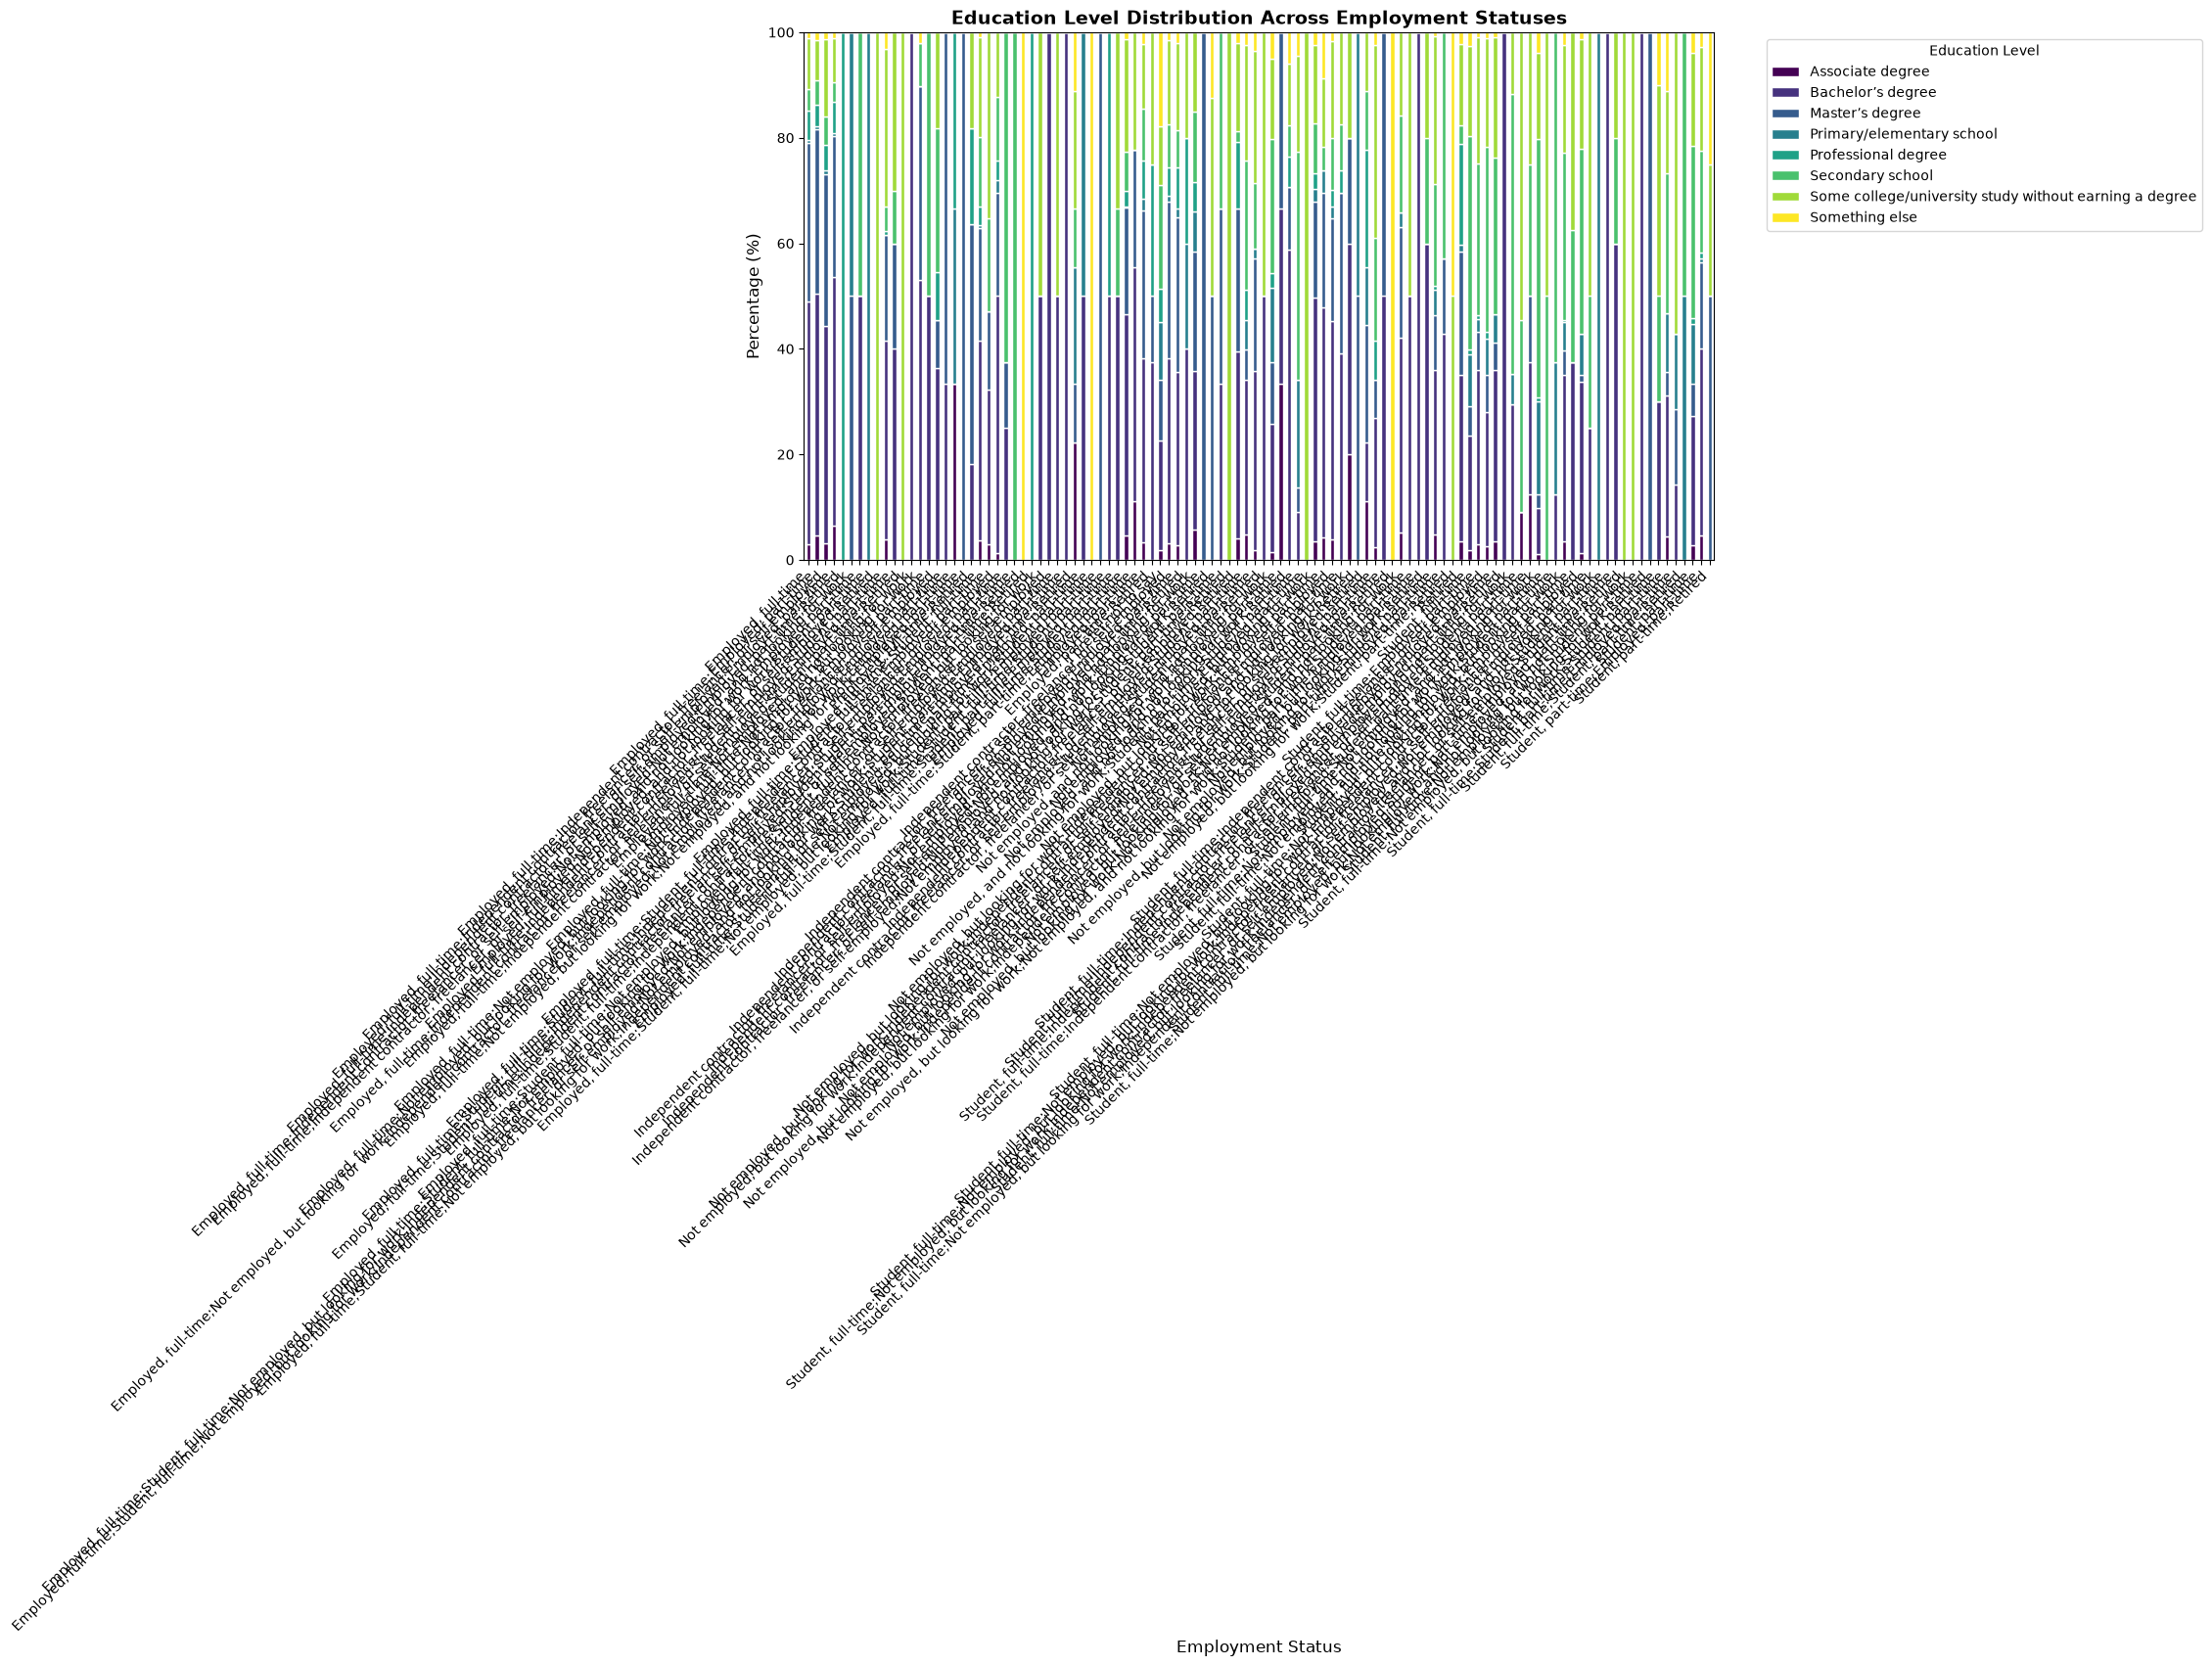

--- Raw Cross-Tabulation Counts ---
EdLevel                                             Associate degree  \
Employment                                                             
Employed, full-time                                             1059   
Employed, full-time;Employed, part-time                            9   
Employed, full-time;Independent contractor, fre...               104   
Employed, full-time;Independent contractor, fre...                11   
Employed, full-time;Independent contractor, fre...                 0   
...                                                              ...   
Student, full-time;Student, part-time;Employed,...                 0   
Student, full-time;Student, part-time;Retired                      0   
Student, part-time                                                12   
Student, part-time;Employed, part-time                            24   
Student, part-time;Retired                                         0   

EdLevel                    

In [10]:
## Write your code here
# 1. Clean the columns by dropping missing records
df_clean = df[['Employment', 'EdLevel']].dropna()

# 2. Shorten long string responses (common in EdLevel) for a cleaner layout
# Example: "Master’s degree (M.A., M.S., M.Eng., MBA, etc.)" -> "Master’s degree"
df_clean['EdLevel'] = df_clean['EdLevel'].str.split(' \(').str[0]

# 3. Create the cross-tabulation matrix (normalized by row to show percentages)
cross_tab = pd.crosstab(df_clean['Employment'], df_clean['EdLevel'], normalize='index') * 100

# 4. Generate the Stacked Bar Plot
ax = cross_tab.plot(kind='bar', stacked=True, figsize=(12, 7), colormap='viridis', edgecolor='white')

plt.title('Education Level Distribution Across Employment Statuses', fontsize=14, fontweight='bold')
plt.xlabel('Employment Status', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Education Level', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 5. Display the raw frequency counts matrix in the console
print("--- Raw Cross-Tabulation Counts ---")
print(pd.crosstab(df_clean['Employment'], df_clean['EdLevel']))

### Step 10: Export Cleaned Data


- Save the cleaned dataset to a new CSV file for further use or sharing.


In [11]:
# 1. Define the filename for your clean data
output_filename = 'Cleaned_Developer_Data.csv'

# 2. Export the DataFrame to a CSV file
df.to_csv(output_filename, index=False)

print(f"--- Export Successful ---")
print(f"The cleaned dataset has been successfully saved to: {output_filename}")

--- Export Successful ---
The cleaned dataset has been successfully saved to: Cleaned_Developer_Data.csv

### Summary:


In this lab, you practiced key skills in exploratory data analysis, including:


- Examining the structure and content of the Stack Overflow survey dataset to understand its variables and data types.

- Identifying and addressing missing data to ensure the dataset's quality and completeness.

- Summarizing and visualizing key variables such as job satisfaction, programming languages, and remote work trends.

- Analyzing relationships in the data using techniques like:
    - Comparing programming languages respondents have worked with versus those they want to work with.
      
    - Exploring remote work preferences by region.

- Investigating correlations between professional coding experience and job satisfaction.

- Performing cross-tabulations to analyze relationships between employment status and education levels.


## Authors:
Ayushi Jain


### Other Contributors:
Rav Ahuja
Lakshmi Holla
Malika


Copyright © IBM Corporation. All rights reserved.
